In [5]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt, colors

from sklearn.cross_decomposition import CCA


from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils

In [6]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [7]:
dims = 2
dims_preca = 5

read_ids = list(range(0, 33+1))
# read_ids = [0,   # minrevs
# 			1,   # minswitch
# 			7,   # maxswitch
# 			11,  # median
# 			12,  # maxrevs
# 			17,  # mean
# 			19,  # paper
# 			21]  # clean
# read_ids = [19]
plot_id = 19

In [8]:
# read

path = os.path.join(read_utils.get_data_path(),'exported_data_gcamp')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_data(path, read_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [9]:
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

plot_idx = file_ids.index(plot_id)
# discrete_states = [ds[selection_bhl] for ds in discrete_states]

# manifold

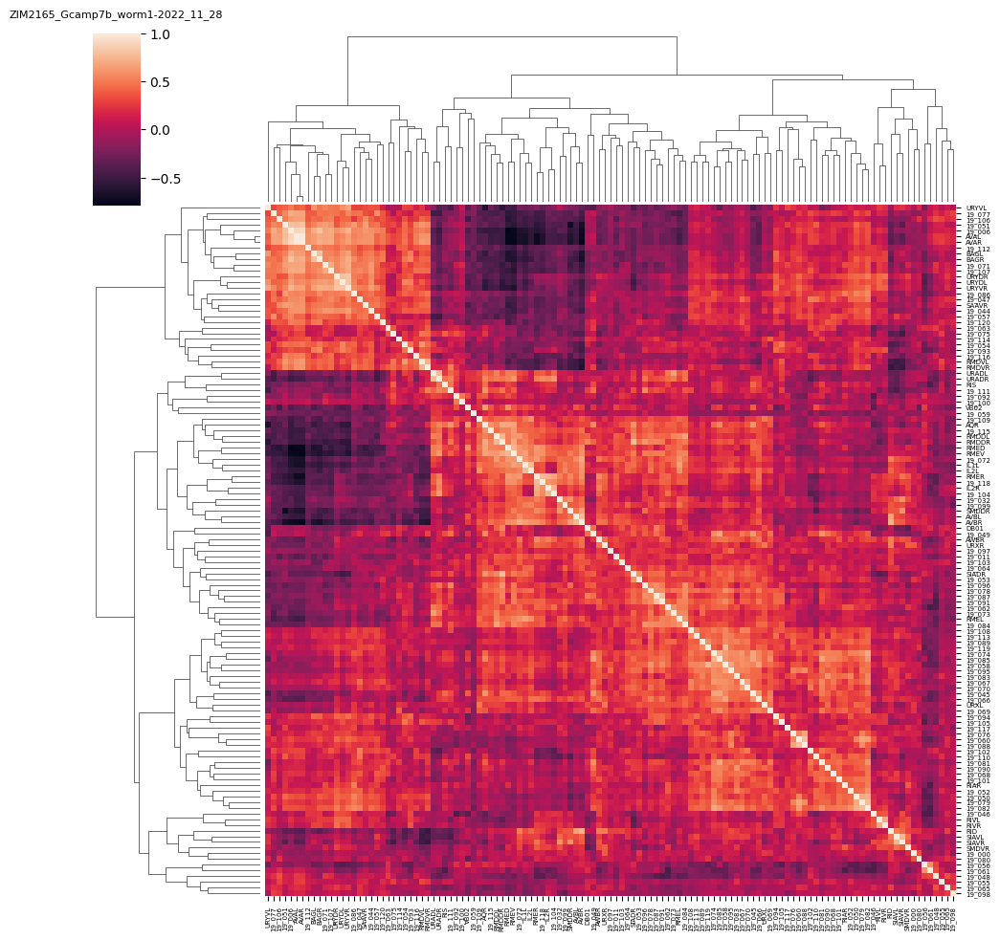

In [10]:
correlations = [trace.corr() for trace in traces]

# plot
heatmap = sns.clustermap(correlations[plot_idx], yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(filenames[plot_idx], fontsize=8, y=1.05)
plt.show()

In [11]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[ds[selection_bhl] for ds in discrete_states],
																	n_cv=dims, n_pc=dims_preca)

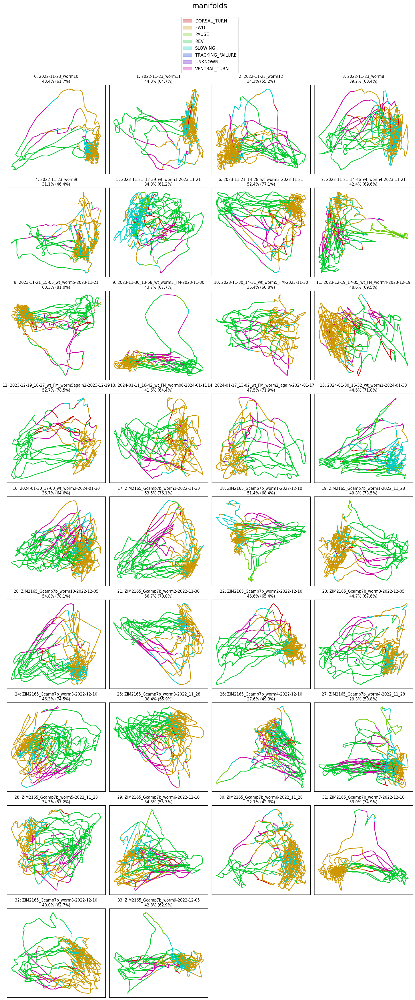

42.9% (32.8%)


In [39]:
# plot
plot_utils.plot_manifolds(
	[f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
	modes_manifold,
	discrete_states,
	vars_expl_mans, vars_expl_mans_rs,
	top_space=3)

In [13]:
traces_manifolds_indices = [np.argsort(xloads_cca_man[:, 0]) for xloads_cca_man in loads_cca_man]
discrete_states_indices = [np.argsort(yloads_cca_man[:, 0])[::-1] for yloads_cca_man in loads_cca_man_b]

discrete_states_sorted = [ds[selection_bhl].iloc[:, ds_idx.tolist()] for ds, ds_idx in zip(discrete_states, discrete_states_indices)]
traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

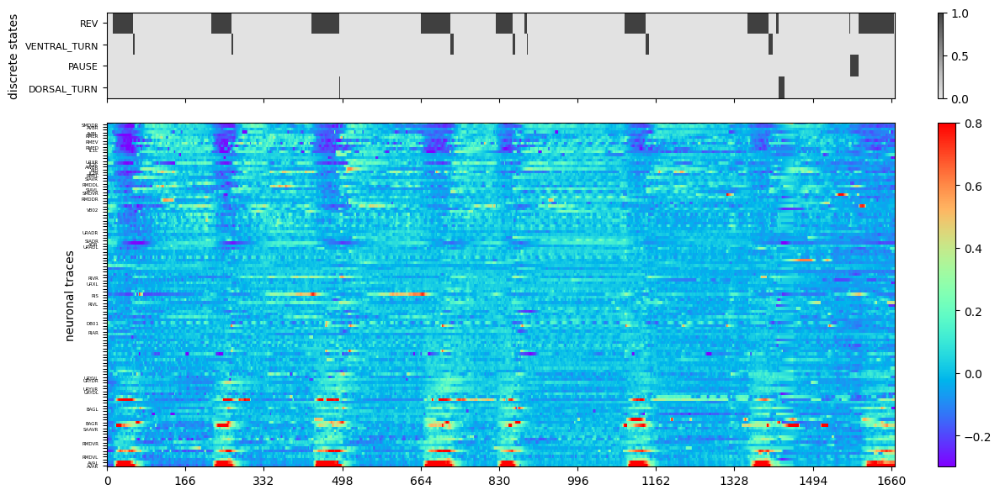

In [14]:
# plot
plot_utils.plot_heatmap_stack(
	traces_sorted[plot_idx],
	discrete_states_sorted[plot_idx],
	'neuronal traces', 'discrete states',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

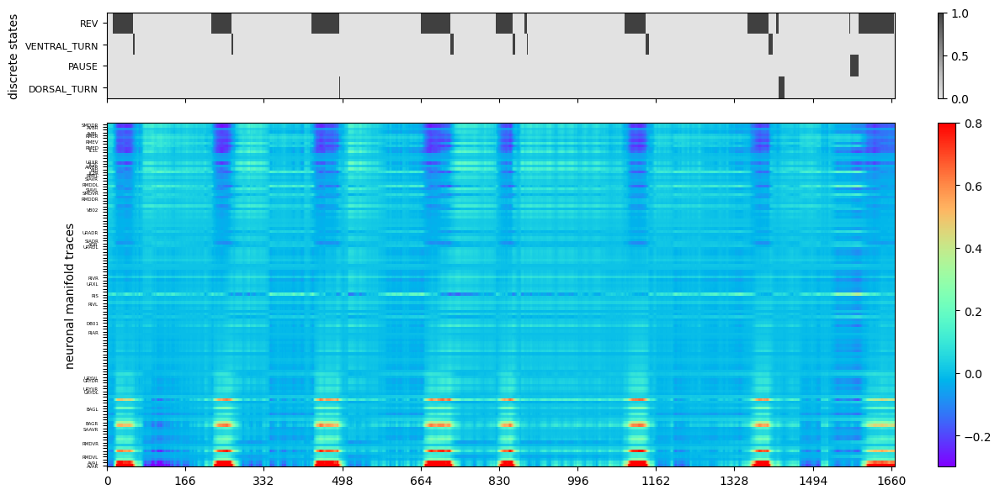

In [15]:
# plot
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[plot_idx],
	discrete_states_sorted[plot_idx],
	'neuronal manifold traces', 'discrete states',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

# concrete behavior

In [16]:
traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]

traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

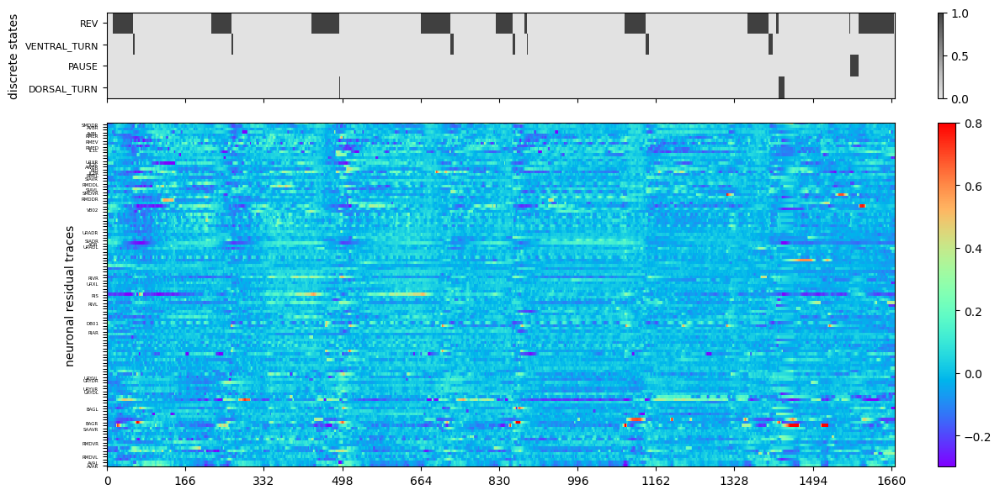

In [17]:
# plot
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[plot_idx],
	discrete_states_sorted[plot_idx],
	'neuronal residual traces', 'discrete states',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

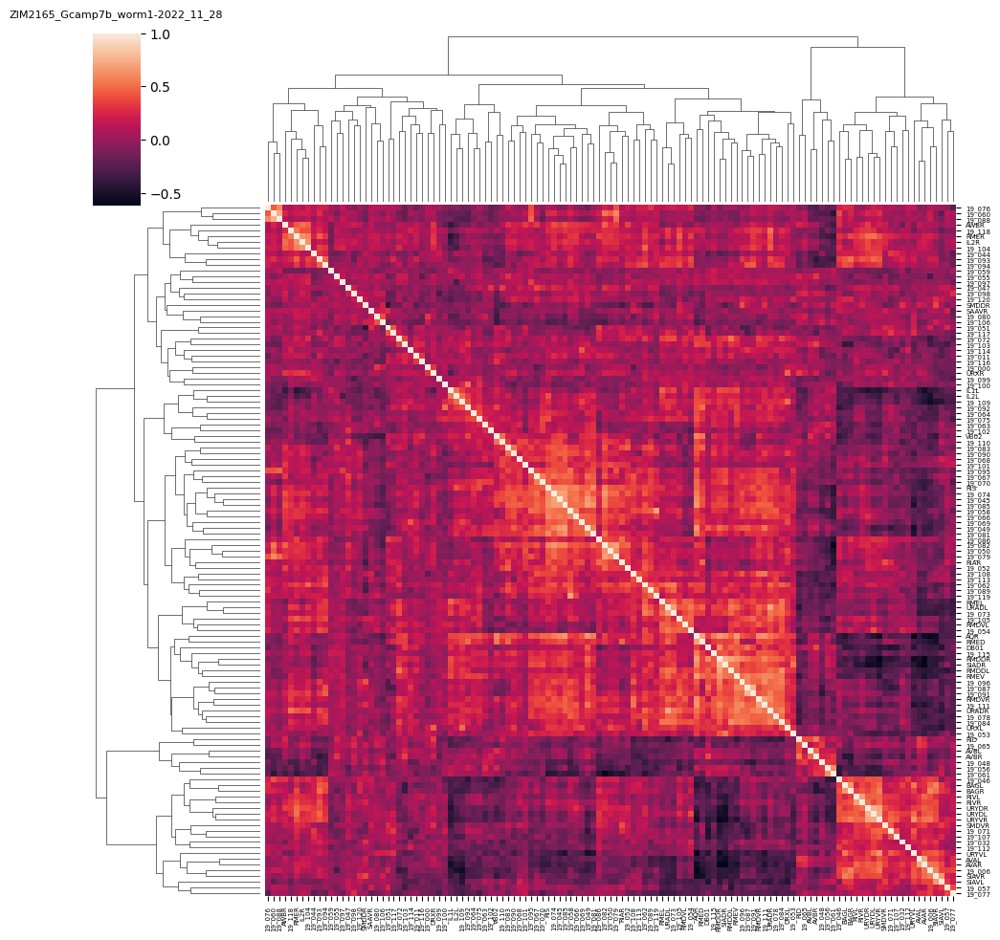

In [18]:
correlations_residuals = [trace_res.corr() for trace_res in traces_residuals]

# plot
heatmap = sns.clustermap(correlations_residuals[plot_idx], xticklabels=True, yticklabels=True)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(filenames[plot_idx], fontsize=8, y=1.05)
plt.show()

In [19]:
n = eigenworms[plot_idx].values.shape[1]

modes_concrete = list()
recos_concrete = list()
loads_cca_con, loads_cca_con_b = list(), list()
vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the residual data
for trace, trace_residual, ew in zip(traces, traces_residuals, eigenworms):
	cca = CCA(n_components=n, scale=True)

	trace_residual_reduced, ew_reduced = cca.fit_transform(trace_residual.values, ew.values)
	trace_residual_reconstructed, ew_reconstructed = cca.inverse_transform(trace_residual_reduced, ew_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CV{i + 1}' for i in range(n)]))
	recos_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	loads_cca_con.append(cca.x_loadings_)
	loads_cca_con_b.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual)
	vars_expl_con.append([var_ratio])
	vars_expl_con_rs.append([var_ratio_rs])

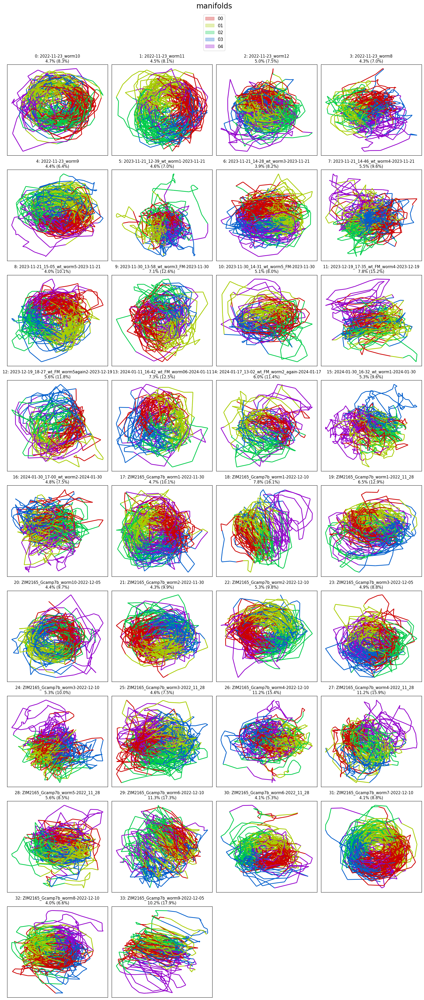

5.9% (10.3%)


In [20]:
# plot
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids], modes_concrete, eigenworms, vars_expl_con, vars_expl_con_rs,
						  top_space=2)

In [21]:
traces_concretes_indices = [np.argsort(xloads_cca_con[:, 0]) for xloads_cca_con in loads_cca_con]
eigenworms_indices = [np.argsort(yloads_cca_con[:, 0])[::-1] for yloads_cca_con in loads_cca_con_b]

eigenworms_sorted = [ew.iloc[:, ew_idx.tolist()] for ew, ew_idx in zip(eigenworms, eigenworms_indices)]
traces_concretes_sorted = [t_con.iloc[:, t_con_idx.tolist()] for t_con, t_con_idx in zip(recos_concrete, traces_concretes_indices)]

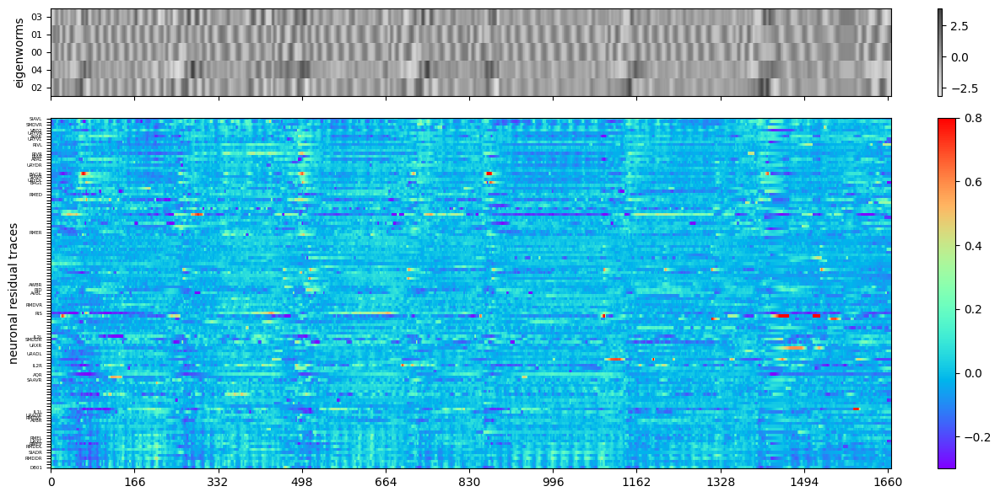

In [22]:
traces_residuals_sorted_by_concretes = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_concretes_indices)]

# plot
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_concretes[plot_idx],
	eigenworms_sorted[plot_idx],
	'neuronal residual traces', 'eigenworms',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

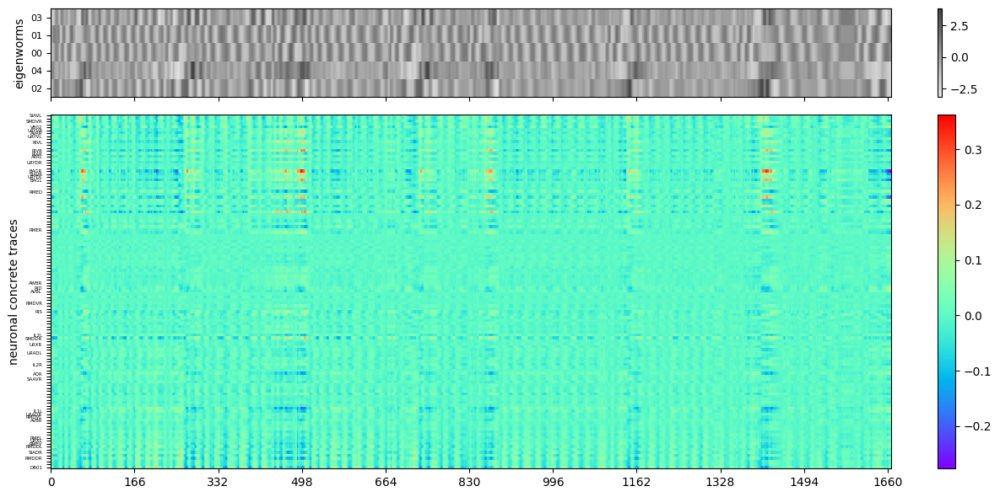

In [23]:
# plot
plot_utils.plot_heatmap_stack(
	traces_concretes_sorted[plot_idx],
	eigenworms_sorted[plot_idx],
	'neuronal concrete traces', 'eigenworms',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

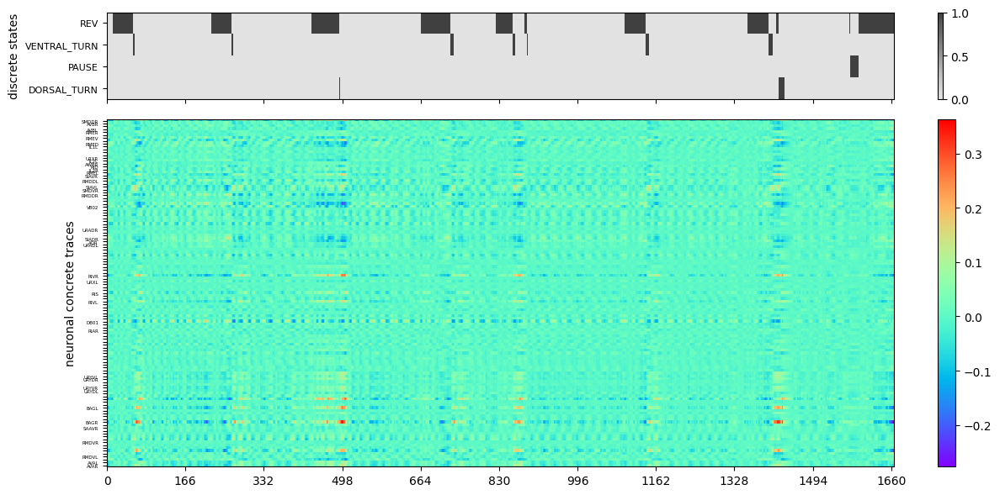

In [24]:
traces_concretes_sorted_by_manifold = [t_con.iloc[:, t_man_idx.tolist()] for t_con, t_man_idx in zip(recos_concrete, traces_manifolds_indices)]

# plot
plot_utils.plot_heatmap_stack(
	traces_concretes_sorted_by_manifold[plot_idx],
	discrete_states_sorted[plot_idx],
	'neuronal concrete traces', 'discrete states',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

# other

In [25]:
traces_others = [pd.DataFrame(data=t_res.values - t_con.values, columns=t_res.columns) for t_res, t_con in zip(traces_residuals, recos_concrete)]

traces_others_sorted_by_concretes = [t_oth.iloc[:, t_con_idx.tolist()] for t_oth, t_con_idx in zip(traces_others, traces_concretes_indices)]

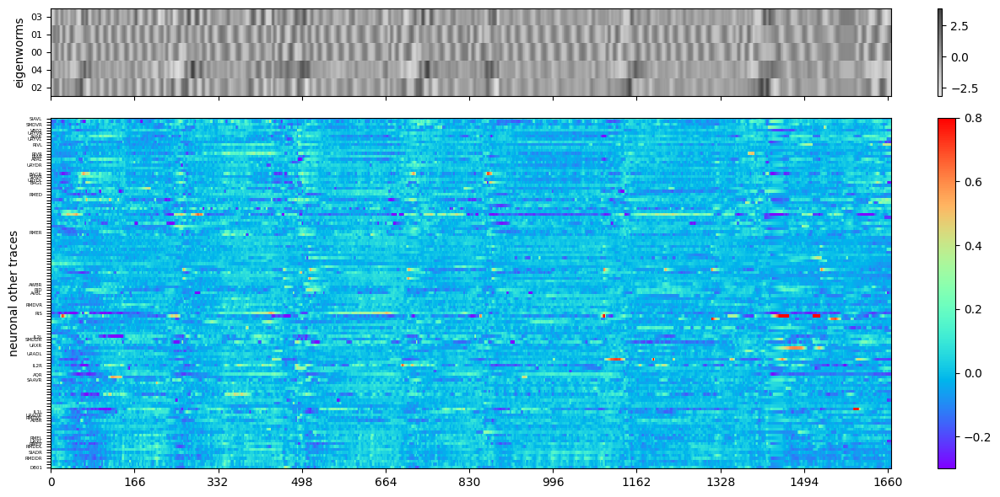

In [26]:
# plot
plot_utils.plot_heatmap_stack(
	traces_others_sorted_by_concretes[plot_idx],
	eigenworms_sorted[plot_idx],
	'neuronal other traces', 'eigenworms',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

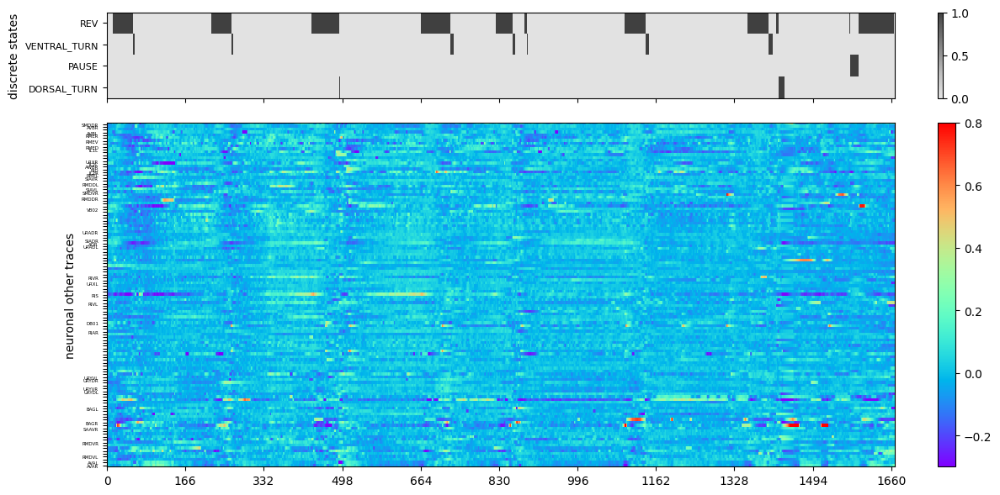

In [27]:
traces_others_sorted_by_manifold = [t_oth.iloc[:, t_man_idx.tolist()] for t_oth, t_man_idx in zip(traces_others, traces_manifolds_indices)]

# plot
plot_utils.plot_heatmap_stack(
	traces_others_sorted_by_manifold[plot_idx],
	discrete_states_sorted[plot_idx],
	'neuronal other traces', 'discrete states',
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

# total reconstruction error

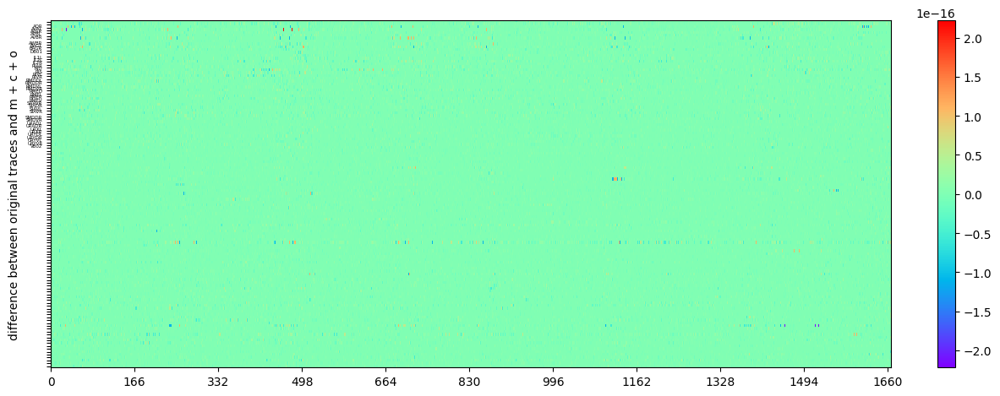

In [28]:
traces_diff = [pd.DataFrame(data=t.values - (t_man.values + t_con.values + t_oth.values), columns=t.columns) for t, t_man, t_con, t_oth in zip(traces, recos_manifold, recos_concrete, traces_others)]

# plot
plot_utils.plot_heatmap_stack(
	traces_diff[plot_idx],
	None,
	'difference between original traces and m + c + o', None,
	zlimits_activity=(-0.3, 0.8), neuron_ids=True)

# variances explained per neuron per dataset

In [29]:
mcos_full = list()
mco_ratios_full = list()
for i in range(len(filenames)):

	traces_all_var = np.var(traces[i].values, axis=0)
	traces_res_var = np.var(traces_residuals[i].values, axis=0)
	traces_man_var = traces_all_var - traces_res_var
	traces_oth_var = np.var(traces_others[i].values, axis=0)
	traces_con_var = traces_res_var - traces_oth_var
	mco = pd.DataFrame(data=np.vstack([traces_all_var, traces_man_var, traces_res_var, traces_con_var, traces_oth_var]),
					   columns=traces[i].columns,
					   index=['a', 'm', 'r', 'c', 'o'])
	mcos_full.append(mco)

	traces_all_var_ratio = traces_all_var / traces_all_var
	traces_res_var_ratio = traces_res_var / traces_all_var
	traces_man_var_ratio = traces_man_var / traces_all_var
	traces_oth_var_ratio = traces_oth_var / traces_all_var
	traces_con_var_ratio = traces_con_var / traces_all_var
	mco_ratio = pd.DataFrame(data=np.vstack([traces_all_var_ratio, traces_man_var_ratio, traces_res_var_ratio, traces_con_var_ratio, traces_oth_var_ratio]),
							 columns=traces[i].columns,
							 index=['a', 'm', 'r', 'c', 'o'])
	mco_ratios_full.append(mco_ratio)


neurons_labels = [traces[i].columns for i in range(len(filenames))]
unique_labels_full = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels = [label for label in unique_labels_full if label != '' and label[-1] != '_']

mcos = list()
for mco in mcos_full:
	mco_filtered = mco[sorted(list(set(unique_labels) & set(mco.columns)))]
	if len(mco_filtered.columns) > 0:
		mcos.append(mco_filtered)
mco_ratios = list()
for mco_ratio in mco_ratios_full:
	mco_ratio_filtered = mco_ratio[sorted(list(set(unique_labels) & set(mco_ratio.columns)))]
	if len(mco_ratio_filtered.columns) > 0:
		mco_ratios.append(mco_ratio_filtered)

# variances explained per neuron averaged over datasets

In [30]:
mcos_avg = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
mcos_std = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
for neuron in unique_labels:
	amrco = {'a': [], 'm': [], 'r': [], 'c': [], 'o': []}
	for mco in mcos:
		if neuron in mco.columns:
			for key in amrco.keys():
				amrco[key].append(mco[neuron][key])
	mcos_avg[neuron] = [np.mean(np.array(amrco[key])) for key in amrco.keys()]
	mcos_std[neuron] = [np.std(np.array(amrco[key])) for key in amrco.keys()]

In [31]:
mco_ratios_avg = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
mco_ratios_std = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
for neuron in unique_labels:
	amrco_ratio = {'a': [], 'm': [], 'r': [], 'c': [], 'o': []}
	for mco_ratio in mco_ratios:
		if neuron in mco_ratio.columns:
			for key in amrco_ratio.keys():
				amrco_ratio[key].append(mco_ratio[neuron][key])
	mco_ratios_avg[neuron] = [np.mean(np.array(amrco_ratio[key])) for key in amrco_ratio.keys()]
	mco_ratios_std[neuron] = [np.std(np.array(amrco_ratio[key])) for key in amrco_ratio.keys()]

# M-C-O ratio bar plots

Average m: 37.0%
Average c: 7.9%
Average o: 55.1%


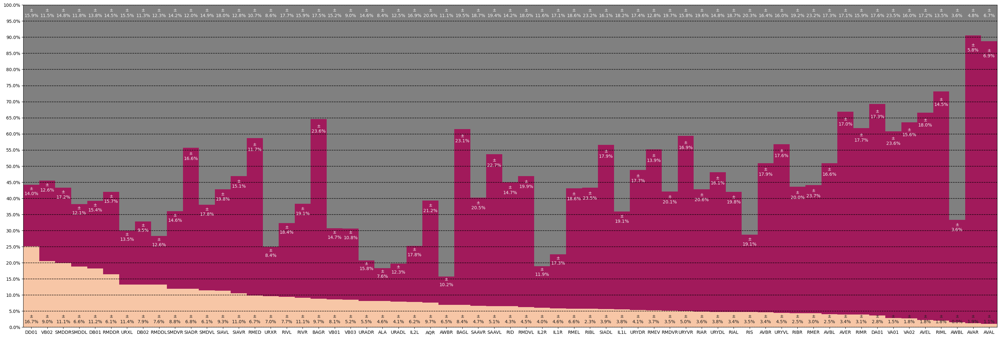

In [32]:
mco_ratio_c_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='c', ascending=False).T
mco_ratio_c_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_c_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_c_avg, [column for column in mco_ratio_c_avg.columns if not column[0].isdigit()],
					 mco_ratio_c_std[[column for column in mco_ratio_c_std.columns if not column[0].isdigit()]],
					 order=('c', 'm', 'o'))

Average m: 37.0%
Average c: 7.9%
Average o: 55.1%


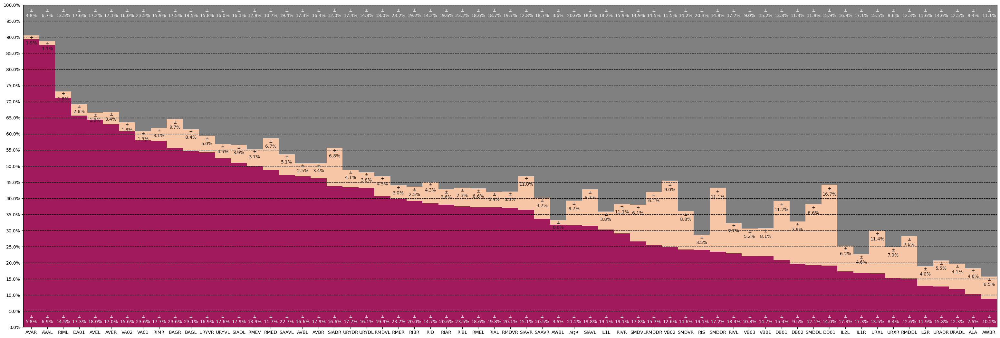

In [33]:
mco_ratio_m_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='m', ascending=False).T
mco_ratio_m_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_m_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_m_avg, [column for column in mco_ratio_m_avg.columns if not column[0].isdigit()],
					 mco_ratio_m_std[[column for column in mco_ratio_m_std.columns if not column[0].isdigit()]],
					 order=('m', 'c', 'o'))

Average m: 37.0%
Average c: 7.9%
Average o: 55.1%


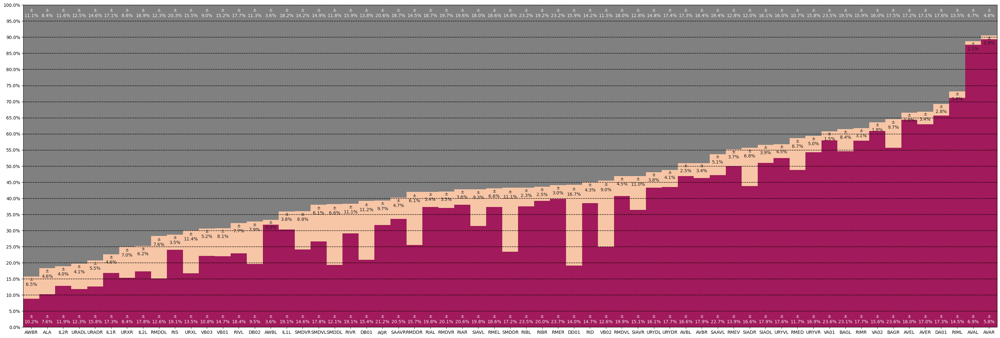

In [34]:
mco_ratio_o_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='o', ascending=False).T
mco_ratio_o_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_o_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_o_avg, [column for column in mco_ratio_o_avg.columns if not column[0].isdigit()],
					 mco_ratio_o_std[[column for column in mco_ratio_o_std.columns if not column[0].isdigit()]],
					 order=('m', 'c', 'o'))

# M-C-O bar plots

Average m: 1.1%
Average c: 0.1%
Average o: 0.7%


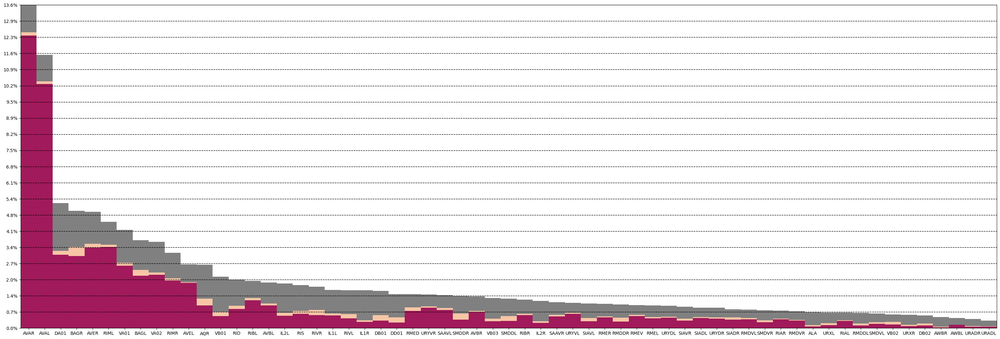

In [35]:
mco_m_avg = mcos_avg.T.sort_values(by='a', ascending=False)[['m', 'c', 'o']].T
mco_m_std = mcos_std.T.reindex(mco_m_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_m_avg, [column for column in mco_m_avg.columns if not column[0].isdigit()],
					 mco_m_std[[column for column in mco_m_std.columns if not column[0].isdigit()]],
					 order=('m', 'c', 'o'),
					 normalized=False)

Average m: 1.1%
Average c: 0.1%
Average o: 0.7%


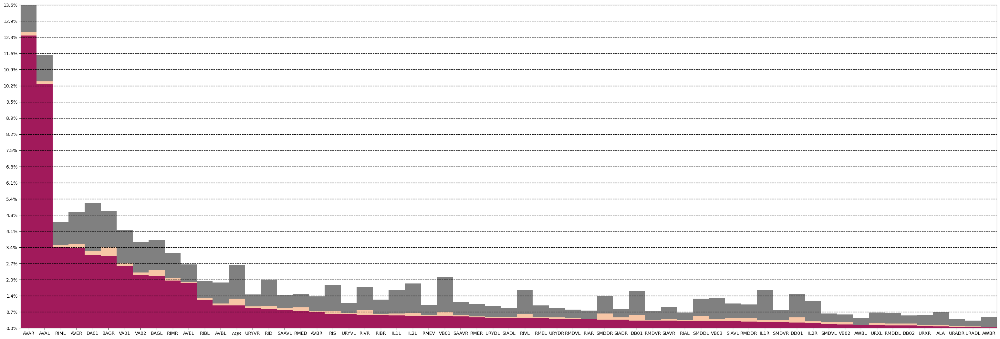

In [36]:
mco_m_avg = mcos_avg.T.sort_values(by='m', ascending=False)[['m', 'c', 'o']].T
mco_m_std = mcos_std.T.reindex(mco_m_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_m_avg, [column for column in mco_m_avg.columns if not column[0].isdigit()],
					 mco_m_std[[column for column in mco_m_std.columns if not column[0].isdigit()]],
					 order=('m', 'c', 'o'),
					 normalized=False)

Average m: 1.1%
Average c: 0.1%
Average o: 0.7%


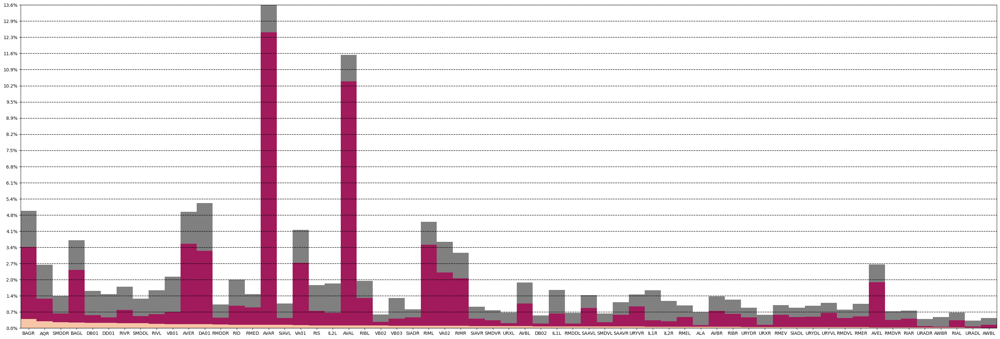

In [37]:
mco_c_avg = mcos_avg.T.sort_values(by='c', ascending=False)[['m', 'c', 'o']].T
mco_c_std = mcos_std.T.reindex(mco_c_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_c_avg, [column for column in mco_c_avg.columns if not column[0].isdigit()],
					 mco_c_std[[column for column in mco_c_std.columns if not column[0].isdigit()]],
					 order=('c', 'm', 'o'),
					 normalized=False)

Average m: 1.1%
Average c: 0.1%
Average o: 0.7%


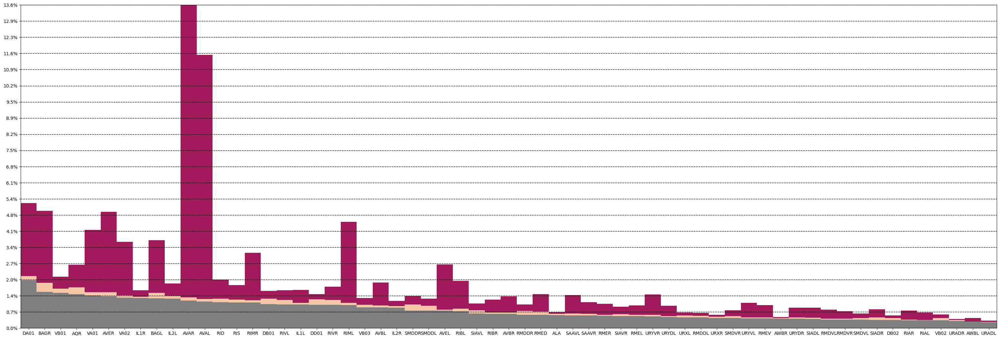

In [38]:
mco_o_avg = mcos_avg.T.sort_values(by='o', ascending=False)[['m', 'c', 'o']].T
mco_o_std = mcos_std.T.reindex(mco_o_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_o_avg, [column for column in mco_o_avg.columns if not column[0].isdigit()],
					 mco_o_std[[column for column in mco_o_std.columns if not column[0].isdigit()]],
					 order=('o', 'c', 'm'),
					 normalized=False)